## T3 de aplicações de Aprendizado de Máquina

### Nome: Victor Hugo 
### NUSP: 11320901

### Prof. Dr. Fabio Lobato

## Objetivo

Construir um classificador que identifica o **idioma** de áudios telefônicos — **português (pt-PT)** ou **espanhol (es-ES)** — usando o dataset **MINDS-14** (PolyAI), com engenharia de atributos e um classificador clássico de aprendizado de máquina.

**Pipeline:**
1. Carregamento do MINDS-14 e seleção dos dois idiomas.
2. Exploração: quantidade de áudios, taxa de amostragem e duração.
3. Pré-processamento: filtro passa-banda de 300 a 3400 Hz (faixa da voz telefônica).
4. Extração de atributos: MFCC, resumido por média e desvio padrão de cada coeficiente (24 atributos por áudio).
5. Classificação: SVM com kernel RBF, com hiperparâmetros escolhidos por *Grid Search* com validação cruzada.
6. Avaliação no conjunto de teste e comparação com um baseline.

In [1]:
!pip install librosa "datasets<4" soundfile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 2.7 MB/s eta 0:00:00
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: datasets
    Found existing installation: datasets 5.0.0
    Uninstalling datasets-5.0.0:
      Successfully uninstalled datasets-5.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tpot 1.1.0 requires dill>=0.3.9, but you have dill 0.3.8 which is incompatible.


## Importação de Libs e carregamento de dataset

O MINDS-14 é carregado do Hugging Face com todos os idiomas e filtrado para **pt-PT** e **es-ES**. Os áudios são mantidos como bytes do arquivo (`decode=False`) e lidos com `soundfile` quando necessário.

In [2]:
from datasets import load_dataset, Audio
import io
import librosa
import matplotlib.pyplot as plt
import pandas as pd
import soundfile as sf
from IPython.display import display
import numpy as np
from scipy.signal import butter, sosfiltfilt

# parâmetros do pré-processamento e do MFCC (justificados nas seções correspondentes)
F_LOW, F_HIGH = 300, 3400   # faixa do filtro passa-banda (voz telefônica), em Hz
SR = 8000                   # taxa de amostragem dos áudios do MINDS-14
WIN = int(0.020 * SR)       # janela de 20 ms = 160 amostras
HOP = int(0.010 * SR)       # passo de 10 ms = 80 amostras
N_FFT = 256                 # tamanho da FFT (janela completada com zeros até potência de 2)
N_MELS = 40                 # número de filtros mel

ds = load_dataset("PolyAI/minds14","all",split="train")
ds = ds.cast_column("audio", Audio(decode=False))
idiomas = ds.features["lang_id"]
intent_class = ds.features["intent_class"]
alvo = {idiomas.str2int("pt-PT"), idiomas.str2int("es-ES")}
ds = ds.filter(lambda lang: lang in alvo, input_columns=["lang_id"])

README.md: 0.00B [00:00, ?B/s]

all/train-00000-of-00002.parquet:   0%|          | 0.00/260M [00:00<?, ?B/s]

all/train-00001-of-00002.parquet:   0%|          | 0.00/307M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/8168 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8168 [00:00<?, ? examples/s]

## Exploração dos Dados

In [3]:
lista_idiomas = ((id,value) for id,value in enumerate(idiomas.names))
idiomas_dict = dict(lista_idiomas)
lista_intents = ((id,value) for id,value in enumerate(intent_class.names))
intents_dict = dict(lista_intents)
df = ds.to_pandas() 
df["lang_name"] = df["lang_id"].map(idiomas_dict)
df["intent_class_name"] = df["intent_class"].map(intents_dict)

### Inventários dos dados

In [4]:
def header(a):
    info = sf.info(io.BytesIO(a["bytes"]))
    return pd.Series({
        "sr": info.samplerate, "channels": info.channels,
        "duration": info.duration, "format": info.format, "subtype": info.subtype,
    })

meta = df["audio"].apply(header)
df[meta.columns] = meta

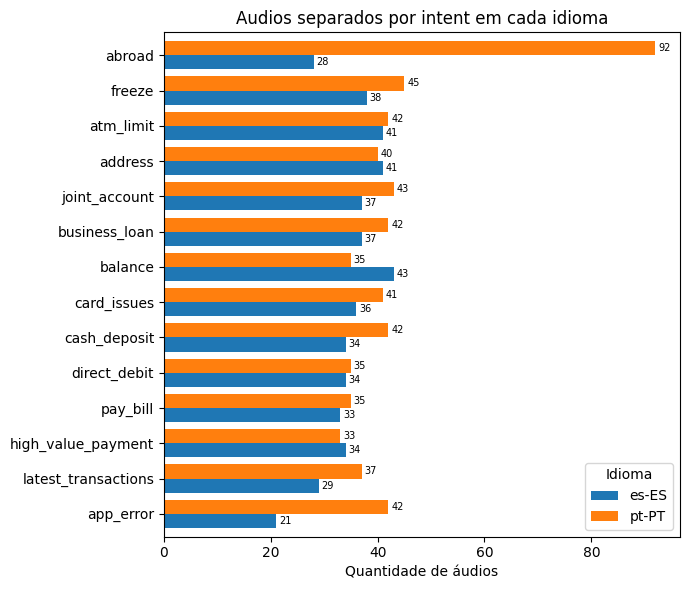

In [5]:
ct = pd.crosstab(df["intent_class_name"], df["lang_name"])
ct = ct.loc[ct.sum(axis=1).sort_values().index]

ax = ct.plot.barh(figsize=(7, 6), width=0.8)
for c in ax.containers:
    ax.bar_label(c, fontsize=7, padding=2) 

ax.set_xlabel("Quantidade de áudios")
ax.set_ylabel("")
ax.set_title("Audios separados por intent em cada idioma")
ax.legend(title="Idioma")
plt.tight_layout()
plt.savefig("distribuicao.pdf")  

O gráfico mostra quantos áudios de cada intenção existem em cada idioma. No MINDS-14, cada áudio é uma pessoa ligando para um banco e pedindo uma de 14 intenções (por exemplo, consultar saldo, abrir conta conjunta, pagar uma conta).

A intenção não é o alvo deste trabalho, mas é útil verificar se ela aparece nos dois idiomas em quantidades parecidas. Se uma intenção existisse só em um idioma, o modelo poderia usar o conteúdo do pedido como atalho em vez do idioma.

### Caracteristicas dos Áudios

In [6]:
desc = df['duration'].describe()
srs_encontrados = ", ".join(str(int(v)) for v in sorted(df['sr'].unique()))
canais_encontrados = ", ".join(str(int(v)) for v in sorted(df['channels'].unique()))

total_audios = int(desc['count'])
duracao_min = round(desc['min'], 2)
duracao_25 = round(desc['25%'], 2) 
duracao_50 = round(desc['50%'], 2)  
duracao_75 = round(desc['75%'], 2) 
duracao_max = round(desc['max'], 2)


dados_resumo = {
    "Métrica": [
        "Total de Áudios", 
        "Taxas de amostragem encontradas (Hz)", 
        "Canais encontrados", 
        "Duração Mínima (s)", 
        "Duração - 1º Quartil (25%)", 
        "Duração - Mediana (50%)",
        "Duração - 3º Quartil (75%)",
        "Duração Máxima (s)"
    ],
    "Valor": [
        total_audios, 
        srs_encontrados, 
        canais_encontrados, 
        duracao_min, 
        duracao_25, 
        duracao_50,
        duracao_75,
        duracao_max
    ]
}

df_resumo = pd.DataFrame(dados_resumo)
display(df_resumo)

,Métrica,Valor
0,Total de Áudios,1090
1,Taxas de amostragem encontradas (Hz),8000
2,Canais encontrados,1
3,Duração Mínima (s),2.05
4,Duração - 1º Quartil (25%),6.57
5,Duração - Mediana (50%),10.56
6,Duração - 3º Quartil (75%),17.29
7,Duração Máxima (s),67.9


Duas características da tabela influenciam as etapas seguintes:

- **Taxa de amostragem de 8 kHz, áudio mono:** a maior frequência representável é 4 kHz (metade da taxa de amostragem). O corte superior do filtro passa-banda, 3400 Hz, fica abaixo desse limite.
- **Duração muito variável** (de cerca de 2 s a 68 s, mediana de cerca de 10,6 s): cada áudio gera uma quantidade diferente de frames. Por isso, na extração de atributos, cada áudio é resumido em um vetor de tamanho fixo.

### Pré-processamento do áudio: filtro passa-banda

Os áudios do MINDS-14 são gravações de **ligações telefônicas** em 8 kHz. A linha telefônica de banda estreita transmite a voz aproximadamente entre **300 Hz e 3400 Hz**; é nessa faixa que está a informação da fala que chega ao áudio.

O que aparece fora dela não é voz transmitida pela linha:
- **Abaixo de 300 Hz:** zumbido da rede elétrica, ruído de manuseio do aparelho, vento, deslocamento constante (*offset DC*) do hardware de captura.
- **Acima de 3400 Hz** (até 4 kHz, o limite de um áudio em 8 kHz): ruído e artefatos do codec.

Por isso é aplicado um **filtro passa-banda de 300 a 3400 Hz**, que mantém só a faixa da voz telefônica. A frequência fundamental de vozes graves (≈ 85–180 Hz) fica abaixo do corte, mas ela já foi removida pelo próprio canal telefônico; os harmônicos acima de 300 Hz permanecem e carregam a informação da fala.

Detalhes do filtro:
- **Butterworth de 4ª ordem:** resposta plana dentro da faixa, sem ondulações.
- **`sosfiltfilt`:** filtra o sinal para frente e para trás, o que deixa a fase em zero. Assim o áudio não é deslocado no tempo.
- **`output="sos"`:** o filtro é dividido em seções de 2ª ordem, numericamente mais estável.

A mesma faixa é passada ao MFCC (`fmin`, `fmax`), para que os filtros mel cubram só a região onde a voz está.

In [7]:
def ler_audio(audio):
    if audio.get("array") is not None:
        return np.asarray(audio["array"], dtype=np.float32), audio["sampling_rate"]
    return sf.read(io.BytesIO(audio["bytes"]), dtype="float32")

def passa_banda(y, sr, low=F_LOW, high=F_HIGH, ordem=4):
    sos = butter(ordem, [low, high], btype="bandpass", fs=sr, output="sos")
    return sosfiltfilt(sos, y).astype(np.float32)

def filtrar_df(df):
    df = df.copy()
    ys, srs = zip(*(ler_audio(a) for a in df["audio"]))
    df["sr"] = srs
    df["y_filt"] = pd.Series([passa_banda(y, sr) for y, sr in zip(ys, srs)],
                             index=df.index, dtype=object)
    return df

def show_soundwave(row_audio, coluna=None, titulo=""):
    if coluna is None:
        y, sr = ler_audio(row_audio["audio"])
    else:
        y, sr = row_audio[coluna], row_audio["sr"]
    t = np.arange(len(y)) / sr
    fig, ax = plt.subplots()
    ax.plot(t, y)
    ax.set_xlabel("Tempo (s)"); ax.set_ylabel("Amplitude"); ax.set_title(titulo)
    plt.ylim(-1, 1); plt.show()

#### Efeito do filtro em uma amostra do dataset

Para visualizar o filtro, são sorteados 10 áudios do dataset inteiro (`random_state=42`, para a amostra ser sempre a mesma).

In [8]:
amostra = filtrar_df(df.sample(10, random_state=42))
display(amostra[["lang_name", "intent_class_name", "duration"]].round(2))

,lang_name,intent_class_name,duration
834,pt-PT,abroad,35.18
940,pt-PT,address,37.56
1084,pt-PT,pay_bill,28.42
1005,pt-PT,freeze,15.53
760,pt-PT,joint_account,31.00
290,es-ES,card_issues,14.42
523,pt-PT,cash_deposit,21.16
192,es-ES,atm_limit,9.30
289,es-ES,card_issues,23.98
954,pt-PT,address,3.84


**Espectro médio da amostra, antes e depois do filtro.** Para cada áudio é calculada a STFT (com a mesma janela usada no MFCC) e tirada a média da magnitude ao longo do tempo; depois, a média entre os 10 áudios. As linhas tracejadas marcam 300 e 3400 Hz.

Dentro da faixa, as duas curvas devem coincidir (o filtro não altera a voz). Fora dela, a curva filtrada deve cair.

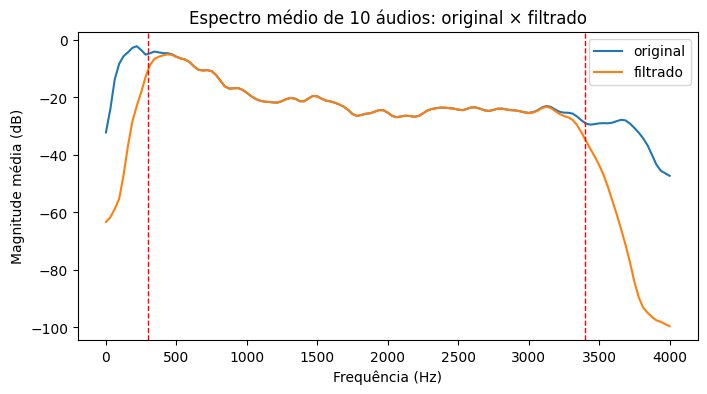

In [9]:
def espectro_medio(y):
    return np.abs(librosa.stft(y, n_fft=N_FFT, win_length=WIN, hop_length=HOP)).mean(axis=1)

freqs = librosa.fft_frequencies(sr=SR, n_fft=N_FFT)
esp_orig = np.mean([espectro_medio(ler_audio(a)[0]) for a in amostra["audio"]], axis=0)
esp_filt = np.mean([espectro_medio(y) for y in amostra["y_filt"]], axis=0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(freqs, 20 * np.log10(esp_orig + 1e-10), label="original")
ax.plot(freqs, 20 * np.log10(esp_filt + 1e-10), label="filtrado")
for f in (F_LOW, F_HIGH):
    ax.axvline(f, color="r", ls="--", lw=1)
ax.set_xlabel("Frequência (Hz)"); ax.set_ylabel("Magnitude média (dB)")
ax.set_title("Espectro médio de 10 áudios: original × filtrado")
ax.legend(); plt.show()

**Forma de onda de um áudio da amostra, antes e depois do filtro.**

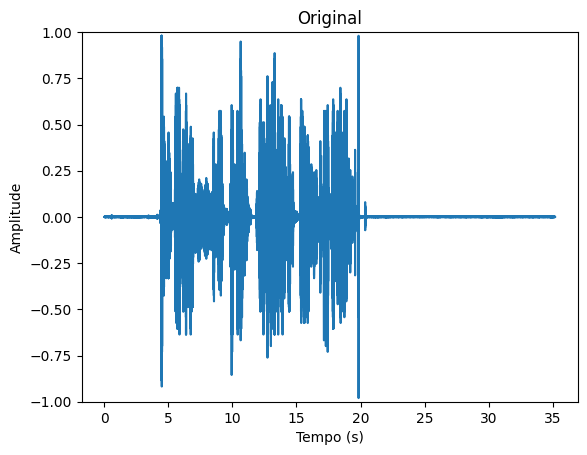

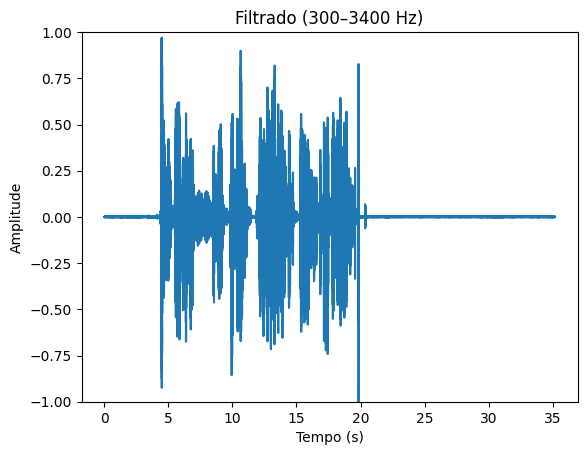

In [10]:
exemplo = amostra.iloc[0]
show_soundwave(exemplo, titulo="Original")
show_soundwave(exemplo, "y_filt", titulo="Filtrado (300–3400 Hz)")

## Extração de atributos

### O que é o MFCC

O **MFCC** (*Mel-Frequency Cepstral Coefficients*) descreve, para cada trecho curto do áudio, o **contorno do espectro**: o formato que o trato vocal (garganta, língua, lábios) dá ao som, e que diferencia um fonema de outro. É calculado em quatro etapas:

1. **STFT:** o áudio é dividido em frames curtos, e o espectro de cada frame é calculado.
2. **Banco de filtros mel:** o espectro é somado em faixas espaçadas na escala mel, estreitas nos graves e largas nos agudos, como a percepção do ouvido.
3. **Log** da energia de cada faixa, como o ouvido percebe intensidade.
4. **DCT:** transforma as energias das faixas em coeficientes. Os primeiros descrevem o contorno suave do espectro (os formantes); os últimos, detalhes finos como a frequência da voz. Ficam os 13 primeiros.

### Parâmetros

| Parâmetro | Valor | Motivo |
|---|---|---|
| Janela (`WIN`) | 20 ms (160 amostras) | A fala é aproximadamente estável em trechos de 20–30 ms, a duração aproximada de um fonema. |
| Passo (`HOP`) | 10 ms (80 amostras) | 50% de sobreposição entre janelas consecutivas, valor padrão em fala. |
| `N_FFT` | 256 | A janela de 160 amostras é completada com zeros até 256, uma potência de 2 (FFT mais rápida). Cada bin cobre 8000 / 256 = 31,25 Hz. |
| `N_MELS` | 40 | Com bins de 31,25 Hz entre 300 e 3400 Hz, muitos mais filtros deixariam os filtros dos graves mais estreitos que um bin, ou seja, vazios. 40 é um valor usual para fala telefônica. |
| `fmin`, `fmax` | 300, 3400 Hz | Mesma faixa do filtro passa-banda. |
| `n_mfcc` | 13 | Quantidade usual em fala: descreve o contorno do espectro sem o detalhe fino. |

### Vetor de atributos

O SVM precisa de um **vetor de tamanho fixo** para cada áudio. O MFCC de um áudio é uma matriz de 13 coeficientes × N frames, e N muda conforme a duração. Para resolver isso, cada coeficiente é resumido ao longo do tempo pela **média** e pelo **desvio padrão**.

Para cada áudio:
1. Leitura e filtro passa-banda (300–3400 Hz).
2. MFCC com os parâmetros acima.
3. Descarte do **MFCC 0**, que representa a energia do frame (volume). O volume da gravação não informa o idioma.
4. Média e desvio de cada um dos 12 coeficientes restantes → **24 atributos por áudio**.

Por isso **não é aplicada normalização de volume**: multiplicar o áudio por um ganho altera só o MFCC 0, que já é descartado. Os coeficientes 1 a 12 não dependem do volume da gravação.

In [11]:
def extrair_features(audio):
    y, sr = ler_audio(audio)
    y = passa_banda(y, sr)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13,
                                n_fft=N_FFT, win_length=WIN, hop_length=HOP,
                                n_mels=N_MELS, fmin=F_LOW, fmax=F_HIGH)
    mfcc = mfcc[1:]   # descarta o MFCC 0 (volume)
    return np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)])

X = np.stack(df["audio"].apply(extrair_features).to_list())
y = df["lang_name"].to_numpy()

nomes_features = [f"mfcc{i}_media" for i in range(1, 13)] + [f"mfcc{i}_desvio" for i in range(1, 13)]
print(X.shape)
display(pd.DataFrame(X, columns=nomes_features).describe().round(2))

(1090, 24)


,mfcc1_media,mfcc2_media,mfcc3_media,mfcc4_media,mfcc5_media,mfcc6_media,mfcc7_media,mfcc8_media,mfcc9_media,mfcc10_media,...,mfcc3_desvio,mfcc4_desvio,mfcc5_desvio,mfcc6_desvio,mfcc7_desvio,mfcc8_desvio,mfcc9_desvio,mfcc10_desvio,mfcc11_desvio,mfcc12_desvio
count,1090.00,1090.00,1090.00,1090.00,1090.00,1090.00,1090.00,1090.00,1090.00,1090.00,...,1090.00,1090.00,1090.00,1090.00,1090.00,1090.00,1090.00,1090.00,1090.00,1090.00
mean,27.30,7.78,7.32,1.55,1.17,-0.47,0.57,-1.80,-0.33,-1.00,...,15.15,11.09,10.48,8.80,7.76,7.17,6.53,6.10,5.83,5.47
std,11.30,7.01,5.73,4.81,3.08,2.93,2.58,2.37,1.99,1.60,...,3.53,2.54,2.33,1.91,1.59,1.42,1.29,1.25,1.24,1.30
min,0.22,-20.30,-13.29,-16.51,-10.25,-13.37,-10.70,-13.41,-8.72,-5.98,...,5.70,4.06,3.72,3.08,2.85,2.37,2.43,2.37,1.97,2.00
25%,19.35,3.47,3.34,-0.54,-0.58,-2.09,-0.85,-3.18,-1.45,-1.92,...,12.62,9.41,8.96,7.58,6.79,6.27,5.80,5.41,5.15,4.78
50%,26.61,7.33,6.64,1.53,1.09,-0.62,0.49,-1.48,-0.26,-1.05,...,14.98,10.91,10.48,8.76,7.75,7.13,6.46,6.05,5.76,5.33
75%,34.94,11.94,11.09,3.95,2.82,1.08,2.01,-0.46,0.81,-0.11,...,17.56,12.67,12.01,9.96,8.69,8.06,7.18,6.79,6.47,5.95
max,67.09,30.73,27.98,18.42,12.21,12.17,9.04,6.72,7.71,5.37,...,27.84,20.06,18.12,17.24,14.46,12.37,11.79,13.17,16.02,14.64


## Classes e referência mínima (baseline)

Antes de treinar, é preciso saber quanto se acerta **sem aprender nada**. Se um idioma tem mais áudios, chutar sempre ele já acerta a proporção dessa classe. Esse é o valor que o SVM precisa superar.

In [12]:
display(df["lang_name"].value_counts().to_frame("quantidade")
        .assign(proporcao=lambda t: (t["quantidade"] / t["quantidade"].sum()).round(3)))

,quantidade,proporcao
lang_name,,
pt-PT,604,0.554
es-ES,486,0.446


## Divisão treino e teste

- **80% treino / 20% teste.**
- **Estratificada por idioma:** treino e teste ficam com a mesma proporção de cada idioma.
- **`random_state=42`:** a divisão é sempre a mesma, o que deixa o resultado reprodutível.

O conjunto de teste **só é usado na avaliação final**. Toda escolha de hiperparâmetros é feita apenas com o treino; se o teste fosse usado para escolher, o resultado final ficaria otimista.

In [13]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("treino:", X_tr.shape, "| teste:", X_te.shape)

treino: (872, 24) | teste: (218, 24)


**Baseline:** um classificador que sempre responde a classe mais frequente do treino.

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

baseline = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
y_base = baseline.predict(X_te)
print(f"baseline  acurácia = {accuracy_score(y_te, y_base):.3f}   F1 macro = {f1_score(y_te, y_base, average='macro'):.3f}")

baseline  acurácia = 0.555   F1 macro = 0.357


## SVM e otimização de hiperparâmetros

O **SVM** (*Support Vector Machine*) procura a fronteira que separa os dois idiomas deixando a **maior margem possível** entre ela e os pontos de cada lado. Com o kernel **RBF**, essa fronteira pode ser curva.

Dois hiperparâmetros controlam o comportamento:

| Hiperparâmetro | O que controla | Valor baixo | Valor alto |
|---|---|---|---|
| `C` | Quanto o modelo é punido por errar no treino | Fronteira suave, tolera erros (risco de *underfitting*) | Tenta acertar todos os pontos do treino (risco de *overfitting*) |
| `gamma` | Até onde vai a influência de cada ponto de treino | Cada ponto influencia uma região grande → fronteira simples | Cada ponto influencia só sua vizinhança → fronteira muito recortada |

**Como os valores são escolhidos (Grid Search com validação cruzada):**
1. Define-se uma grade de valores para `C` e `gamma` (aqui, 4 × 5 = 20 combinações).
2. Para cada combinação, o **treino** é dividido em 5 partes (*folds*). O modelo treina em 4 e é avaliado na 5ª, repetindo 5 vezes, uma vez para cada parte.
3. A combinação com a melhor média nas 5 avaliações é escolhida e o modelo é retreinado com ela em todo o treino.

**A grade testada:**
- `C`: 0,1, 1, 10 e 100.
- `gamma`: 0,001, 0,01, 0,1 e 1, mais o valor `"scale"`, que é o padrão do scikit-learn: `gamma = 1 / (número de atributos × variância de X)`. Como o `StandardScaler` deixa a variância em 1, ele vale 1/24 ≈ 0,042.

Os valores são espaçados em escala logarítmica (multiplicando por 10) para cobrir várias ordens de grandeza com poucas combinações.

A métrica usada para escolher é o **F1 macro**, que dá o mesmo peso aos dois idiomas mesmo que um tenha mais áudios.

O `StandardScaler` fica dentro do pipeline: ele coloca os 24 atributos na mesma escala (média 0, desvio 1). Isso é necessário porque o SVM usa distâncias, e um atributo com valores maiores dominaria os outros. Dentro do pipeline, a escala é calculada só com os dados de treino de cada fold.

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

modelo = make_pipeline(StandardScaler(), SVC(kernel="rbf"))

grade = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.001, 0.01, 0.1, 1],
}

busca = GridSearchCV(
    modelo, grade,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="f1_macro",
    n_jobs=-1,
)
busca.fit(X_tr, y_tr)

print("melhores hiperparâmetros:", busca.best_params_)
print(f"F1 macro médio na validação cruzada: {busca.best_score_:.3f}")

melhores hiperparâmetros: {'svc__C': 100, 'svc__gamma': 0.1}
F1 macro médio na validação cruzada: 0.870


Resultado de todas as combinações na validação cruzada (F1 macro médio). Mostra o quanto o desempenho depende de `C` e `gamma`, e se o melhor valor ficou na borda da grade (o que indicaria que vale testar valores além dela).

In [16]:
resultados = pd.DataFrame(busca.cv_results_)
tabela_cv = resultados.pivot_table(index="param_svc__C", columns="param_svc__gamma",
                                   values="mean_test_score", aggfunc="first")
display(tabela_cv.round(3))

param_svc__gamma,0.001,0.01,0.1,1,scale
param_svc__C,,,,,
0.1,0.356,0.721,0.747,0.356,0.745
1.0,0.714,0.751,0.832,0.405,0.790
10.0,0.715,0.791,0.870,0.431,0.848
100.0,0.768,0.821,0.870,0.431,0.843


## Avaliação no conjunto de teste

O modelo com os melhores hiperparâmetros é avaliado uma única vez no conjunto de teste, que não participou de nenhuma escolha.

- **Precision:** dos áudios classificados como um idioma, quantos eram mesmo daquele idioma.
- **Recall:** dos áudios de um idioma, quantos o modelo reconheceu.
- **F1:** média harmônica entre precision e recall.
- **Matriz de confusão:** linhas são o idioma real, colunas o previsto; a diagonal são os acertos.

              precision    recall  f1-score   support

       es-ES      0.796     0.804     0.800        97
       pt-PT      0.842     0.835     0.838       121

    accuracy                          0.821       218
   macro avg      0.819     0.819     0.819       218
weighted avg      0.821     0.821     0.821       218



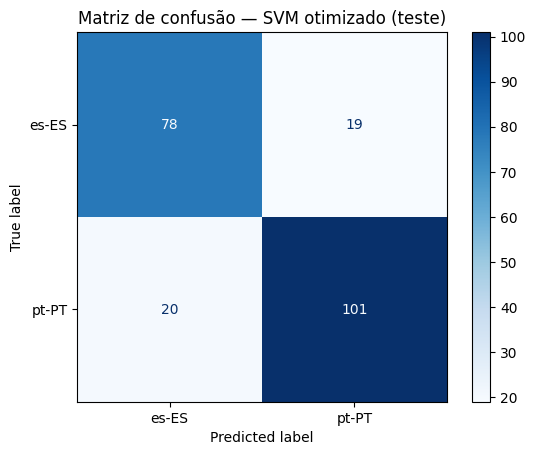

In [17]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

y_pred = busca.predict(X_te)
print(classification_report(y_te, y_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(y_te, y_pred, cmap="Blues")
plt.title("Matriz de confusão — SVM otimizado (teste)")
plt.show()

In [18]:
resumo = pd.DataFrame({
    "acurácia": [accuracy_score(y_te, y_base), accuracy_score(y_te, y_pred)],
    "F1 macro": [f1_score(y_te, y_base, average="macro"), f1_score(y_te, y_pred, average="macro")],
}, index=["baseline (classe majoritária)", "SVM otimizado"])
display(resumo.round(3))

,acurácia,F1 macro
baseline (classe majoritária),0.555,0.357
SVM otimizado,0.821,0.819


## Análise dos resultados

**Desempenho geral.** O SVM otimizado atingiu **acurácia de 0,821** e **F1 macro de 0,819** no conjunto de teste (218 áudios). O baseline, que sempre responde o idioma majoritário (pt-PT, 55,5% do teste), tem acurácia de 0,555 e F1 macro de 0,357. O modelo fica 26,6 pontos percentuais acima do baseline em acurácia, o que mostra que os atributos de MFCC carregam informação que distingue os dois idiomas.

**Equilíbrio entre os idiomas.** O F1 é de 0,800 para es-ES e 0,838 para pt-PT, com recall de 0,804 e 0,835. Na matriz de confusão, 19 áudios em espanhol foram classificados como português e 20 em português como espanhol: os erros são praticamente simétricos. Mesmo com mais áudios de pt-PT no conjunto (121 contra 97 no teste), o modelo não passou a favorecer essa classe. A pequena vantagem de pt-PT pode refletir a maior quantidade de exemplos de treino desse idioma.

**Hiperparâmetros.** A melhor combinação foi `C = 100` e `gamma = 0,1`, com F1 macro de 0,870 na validação cruzada. A tabela da validação cruzada mostra:
- **`gamma = 1`** teve os piores resultados (0,356 a 0,431). Cada ponto de treino influencia só a vizinhança imediata, e o modelo decora o treino sem generalizar (*overfitting*).
- **`gamma = 0,001` com `C = 0,1`** resultou em 0,356, o mesmo F1 do baseline: a fronteira fica tão suave que o modelo prevê uma única classe (*underfitting*).
- **`gamma = 0,1`** foi o melhor valor em todas as linhas a partir de `C = 1`.
- **`C = 10` e `C = 100` empatam** em 0,870 com `gamma = 0,1`. Embora `C = 100` esteja na borda da grade, aumentar `C` de 10 para 100 não trouxe ganho, o que indica um platô; valores maiores dificilmente melhorariam o resultado.
- **Ganho da otimização:** com os valores padrão do scikit-learn (`C = 1`, `gamma = "scale"`), o F1 macro na validação cruzada é 0,790. A otimização elevou esse valor para 0,870, um ganho de 8 pontos.

**Validação cruzada × teste.** O F1 macro caiu de 0,870 na validação cruzada para 0,819 no teste. A diferença é esperada por dois motivos: (1) escolher a melhor entre 20 combinações tende a superestimar a nota da validação cruzada, porque se seleciona o máximo; (2) o teste tem 218 áudios, o que dá um erro padrão aproximado de ±2,6 pontos percentuais na acurácia (√(0,82 × 0,18 / 218) ≈ 0,026).